# Assessment Notebook

In [1]:
# Numerical arrays
import numpy as np

#  Yahoo Finance data
import yfinance as yf

# Dates and times
import datetime as dt

# Data frames
import pandas as pd

# Plotting
import matplotlib.pyplot as plt

# File system paths
from pathlib import Path

## Problem 1: Downloading Stock Market Data

Problem 1 involves downloading five days of hourly stock market data for five companies: NVIDIA (NVDA), Broadcom (AVGO), Arm (ARM), AMD (AMD), IBM (IBM).

I use the [yfinance](https://github.com/ranaroussi/yfinance) package, it retrieves data from Yahoo Finance. The function `get_data()` does four things:

1. Downloads the data for all five tickers in a single call to `yf.download()`, using `period="5d"` and `interval="1h"`.
2. Creates a `data` folder in the root of repository if it does not already exist.
3. Saves the data as a CSV file named with the download time in the format `YYYYMMDD-HHmmss.csv`, so each run creates a new file and nothing is overwritten.
4. Returns the downloaded data as a pandas DataFrame so it can be used directly.

In [2]:
def get_data():
    # Ticker symbols for the five companies
    tickers = ["NVDA", "AVGO", "ARM", "AMD", "IBM"]

    # One call for all tickers: faster than five separate downloads and gives a single table with the same timestamps for every company
    data = yf.download(tickers, period="5d", interval="1h", progress=False)

    # exist_ok=True so the function does not fail if the folder exists
    data_folder = Path("data")
    data_folder.mkdir(exist_ok=True)

    # Timestamp in the filename means each run creates a new file
    timestamp = dt.datetime.now().strftime("%Y%m%d-%H%M%S")
    filename = data_folder / f"{timestamp}.csv"

    # Save the data, including the multi-level column headers
    data.to_csv(filename)

    return data

Calling the function downloads the data, saves the CSV and returns the DataFrame. `head()` shows the first five rows.

In [3]:
df = get_data()
df.head()

Price                           Close                                      \
Ticker                            AMD         ARM        AVGO         IBM   
Datetime                                                                    
2026-11-02 09:30:00-05:00  507.447998  206.759995  333.489990  258.845001   
2026-11-02 10:30:00-05:00  489.489990  204.979996  330.255005  259.480011   
2026-11-02 11:30:00-05:00  487.545013  203.794998  330.404999  259.417999   
2026-11-02 12:30:00-05:00  480.839996  202.619995  329.214996  257.790009   
2026-11-02 13:30:00-05:00  474.070007  198.759995  325.359985  254.320007   

Price                                        High                          \
Ticker                           NVDA         AMD         ARM        AVGO   
Datetime                                                                    
2026-11-02 09:30:00-05:00  209.809906  512.820007  206.990005  333.519989   
2026-11-02 10:30:00-05:00  206.899994  507.480011  206.664993  333.559906   
2026-11-02 11:30:00-05:00  206.610001  492.149994  205.389999  331.429993   
2026-11-02 12:30:00-05:00  206.565002  487.679993  203.710007  330.480011   
2026-11-02 13:30:00-05:00  204.434998  481.250000  203.110001  329.359985   

Price                                              ...        Open  \
Ticker                            IBM        NVDA  ...         AMD   
Datetime                                           ...               
2026-11-02 09:30:00-05:00  259.035004  209.976898  ...  510.649994   
2026-11-02 10:30:00-05:00  259.839996  209.839996  ...  507.399994   
2026-11-02 11:30:00-05:00  259.869995  207.339996  ...  489.359985   
2026-11-02 12:30:00-05:00  259.399994  207.179993  ...  487.600006   
2026-11-02 13:30:00-05:00  258.213501  206.610001  ...  480.779999   

Price                                                                      \
Ticker                            ARM        AVGO         IBM        NVDA   
Datetime                                                                    
2026-11-02 09:30:00-05:00  206.570007  328.440002  258.119995  207.589996   
2026-11-02 10:30:00-05:00  206.664993  333.500000  258.845001  209.809998   
2026-11-02 11:30:00-05:00  205.029999  330.339996  259.619995  206.910004   
2026-11-02 12:30:00-05:00  203.505005  330.410004  259.390015  206.600006   
2026-11-02 13:30:00-05:00  202.570099  329.190002  257.779999  206.539993   

Price                       Volume                                     
Ticker                         AMD     ARM     AVGO     IBM      NVDA  
Datetime                                                               
2026-11-02 09:30:00-05:00  5702750  936051  4137348  596329  24944381  
2026-11-02 10:30:00-05:00  4096331  652215  1750833  462251  12393720  
2026-11-02 11:30:00-05:00  2622175  505945  1142395  351477   7519230  
2026-11-02 12:30:00-05:00  3669939  453946  1362960  355285   8701681  
2026-11-02 13:30:00-05:00  3670300  804917  1436880  308785   9660111  

[5 rows x 25 columns]

### References
- [yfinance documentation](https://ranaroussi.github.io/yfinance): describes `yf.download()` and its `period` and `interval` arguments, which I use to request five days of hourly data for several tickers at once.
- [Python `pathlib` documentation](https://docs.python.org/3/library/pathlib.html): explains `Path.mkdir(exist_ok=True)`, which I use to create the `data` folder only when it is missing.
- [Python `datetime` documentation: strftime format codes](https://docs.python.org/3/library/datetime.html#strftime-and-strptime-format-codes): explains the codes `%Y%m%d-%H%M%S` that I use to build the timestamp for the filename.

## Problem 2: Plotting the Data

Problem 2 involves plotting the stock data downloaded in Problem  1. The  function `plot_data()`will:

1. Open the most recent CSV file in the `data` folder.
2. Calculate the percentage change in the `Close` price of each company, relative to its first recorded observation.
3. Plot the percentage change for all five companies on the same set of axes.
4. Save the plot in a `plots` folder, named in the format `YYYYMMDD-HHmmss.png`.

### Why percentage change rather than share price?
The five companies trade at very different prices, so plotting the raw `Close` price on one set of axes would mostly show which share is the most expensive, not which one performed best. A $10 rise is only 2$ for a $500 share but 5% for a $200 share, yet on a price chart both would look like the same $10 step, so the movements of the cheaper shares would look much smaller than they really are.

Dividing by each company's first price puts all five on the same scale. Every line starts at 0%, and its height at any time reads directly as the gain or loss since the start, so the lines can be compared fairly. The comparison only covers this one-week window, because every change is measured from the first observation.

### Loading the most recent data
The CSV filenames are timestamps in the format `YYYYMMDD-HHmmss`, so sorting them alphabetically also sorts them by time. The last file in the sorted list is the most recent download. The file has two header rows (price type and ticker), so `header=[0, 1]` tells pandas to read both as column levels.
The data covers a clock change in New York (daylight saving time ended on 1 November), so the timestamps in the file have two different UTC offsets. Pandas cannot read mixed offsets as a single date column, so I convert the index to UTC first and then to New York time, where the stocks trade.

In [4]:
# Sorting the names puts the newest timestamp last
latest_file = sorted(Path("data").glob("*.csv"))[-1]
print(latest_file)

# Two header rows: price type (Close, High, ...) and ticker
prices = pd.read_csv(latest_file, header=[0, 1], index_col=0)

# The data spans the US clock change (-04:00 to -05:00), so pandas cannot parse the index directly. Convert via UTC, then to New York market time.
prices.index = pd.to_datetime(prices.index, utc=True).tz_convert("America/New_York")
prices["Close"].head()

data\20261109-142440.csv


Ticker,AMD,ARM,AVGO,IBM,NVDA
Datetime,,,,,
2026-11-02 09:30:00-05:00,507.447998,206.759995,333.489990,258.845001,209.809906
2026-11-02 10:30:00-05:00,489.489990,204.979996,330.255005,259.480011,206.899994
2026-11-02 11:30:00-05:00,487.545013,203.794998,330.404999,259.417999,206.610001
2026-11-02 12:30:00-05:00,480.839996,202.619995,329.214996,257.790009,206.565002
2026-11-02 13:30:00-05:00,474.070007,198.759995,325.359985,254.320007,204.434998


### Calculating the percentage change
For each company, the percentage change of the `Close` price relative to its first observation is (P_t - P_0) / P_0 × 100, where P_t is the price at time t and P_0 is the first in the data. Pandas applies the formula to every column at once, so each company is calculated against its own first price.

In [5]:
# Close prices only: one column per company
close = prices["Close"]

# Subtract and divide by the first row (P_0) of each column, then convert to %
pct_change = (close - close.iloc[0]) / close.iloc[0] * 100
pct_change.head()

Ticker,AMD,ARM,AVGO,IBM,NVDA
Datetime,,,,,
2026-11-02 09:30:00-05:00,0.000000,0.000000,0.000000,0.000000,0.000000
2026-11-02 10:30:00-05:00,-3.538886,-0.860901,-0.970040,0.245324,-1.386928
2026-11-02 11:30:00-05:00,-3.922172,-1.434028,-0.925063,0.221367,-1.525145
2026-11-02 12:30:00-05:00,-5.243493,-2.002321,-1.281896,-0.407577,-1.546592
2026-11-02 13:30:00-05:00,-6.577618,-3.869220,-2.437856,-1.748148,-2.561799


### Plotting the percentage change
All five companies go on the same axes. Each line has its own colour and line style, so they stay distinguishable. The percentage change starts at 0 for every company, so the lines can be compared even though the share prices differ a lot.The title includes the date range of the data, taken from the first and last timestamps.

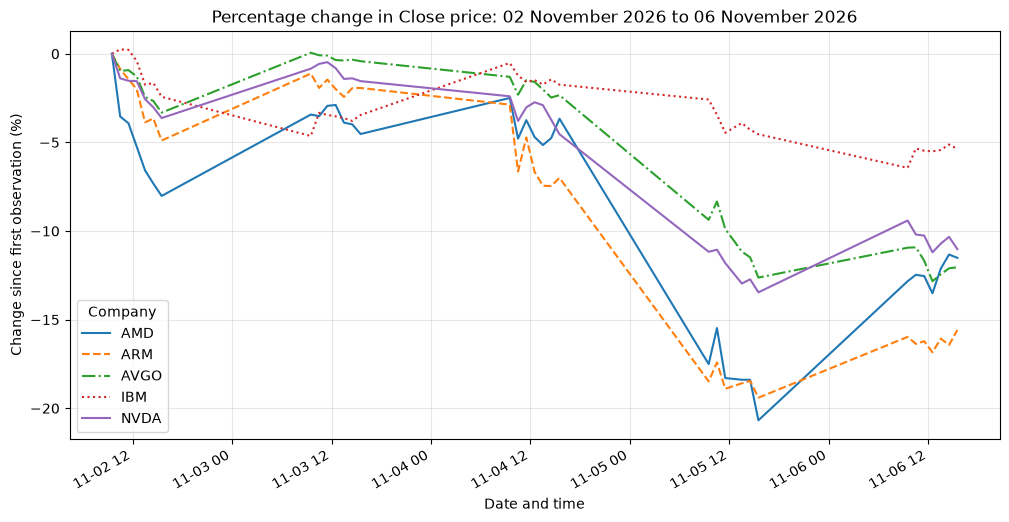

In [6]:
# One colour per company comes from matplotlib's default cycle; the line styles add a second way to tell the series apart
line_styles = ["-", "--", "-.", ":", "-"]

fig, ax = plt.subplots(figsize=(12, 6))

for ticker, style in zip(pct_change.columns, line_styles):
    ax.plot(pct_change.index, pct_change[ticker], linestyle=style, label=ticker)

# Date range of the data for the title
start = pct_change.index[0]
end = pct_change.index[-1]

ax.set_title(f"Percentage change in Close price: {start:%d %B %Y} to {end:%d %B %Y}")
ax.set_xlabel("Date and time")
ax.set_ylabel("Change since first observation (%)")
ax.legend(title="Company")
ax.grid(alpha=0.3)

# Tilt the date labels so they do not overlap
fig.autofmt_xdate()
plt.show()

### The `plot_data()` function
The function combines the steps above into one resusable function. It finds the newest CSV in `data/`, calculates the percentage change , draws the plot and saves it in `plots/`. The PNG gets the same timestamp as the CSV it made from (`YYYYMMDD-HHmmss.png`), so each plot can be matched to its data file. The `plots`folder is created if it does not exist.

In [7]:
def plot_data():
    # Newest file last, because the timestamped names sort chronologically
    csv_files = sorted(Path("data").glob("*.csv"))
    if not csv_files:
        raise FileNotFoundError("No CSV files in data/. Run get_data() first.")
    latest_file = csv_files[-1]

    # Two header rows: price type and ticker
    prices = pd.read_csv(latest_file, header=[0, 1], index_col=0)

    # Mixed UTC offsets (clock change), so convert via UTC to New York time
    prices.index = pd.to_datetime(prices.index, utc=True).tz_convert("America/New_York")

    # Percentage change of Close relative to the first observation (P_0)
    close = prices["Close"]
    pct_change = (close - close.iloc[0]) / close.iloc[0] * 100

    # Different line styles as well as colours keep the series distinguishable
    line_styles = ["-", "--", "-.", ":", "-"]

    fig, ax = plt.subplots(figsize=(12, 6))
    for ticker, style in zip(pct_change.columns, line_styles):
        ax.plot(pct_change.index, pct_change[ticker], linestyle=style, label=ticker)

    start, end = pct_change.index[0], pct_change.index[-1]
    ax.set_title(
        f"Percentage change in Close price: {start:%d %B %Y} to {end:%d %B %Y}"
    )
    ax.set_xlabel("Date and time (New York time)")
    ax.set_ylabel("Change since first observation (%)")
    ax.legend(title="Company")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()

    # Create the plots folder if needed, then save the CSV's timestamp
    plots_folder = Path("plots")
    plots_folder.mkdir(exist_ok=True)
    fig.savefig(plots_folder / f"{latest_file.stem}.png", dpi=150)

    plt.show()

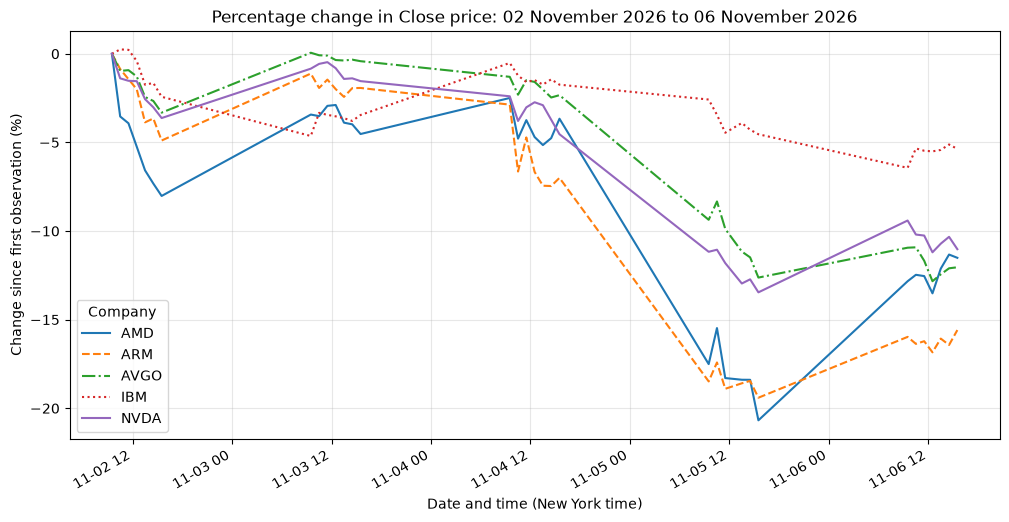

In [8]:
plot_data()

## Problem 3: Creating an Executable Script

Problem 3 involves

## Problem 4: Automating the Analysis with GitHub Actions

Problem 4 involves

## End